## Cargar los datos

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# ==================================================
# 1. LOCALIZAR PROYECTO
# ==================================================

cwd = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        ruta
        for ruta in (cwd, *cwd.parents)
        if (ruta / "data" / "processed").is_dir()
        and (ruta / "notebooks").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se encontró la raíz del proyecto."
    )

# ==================================================
# 2. CARGAR DATASET
# ==================================================

FEATURES_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "panel_features_multihorizonte.parquet"
)

features = pd.read_parquet(FEATURES_PATH)

features["fecha"] = pd.to_datetime(features["fecha"])

HORIZONTES = [1, 2, 3]

for h in HORIZONTES:
    columna = f"fecha_objetivo_t{h}"

    features[columna] = pd.to_datetime(
        features[columna]
    )

# ==================================================
# 3. DEFINIR CARACTERÍSTICAS
# ==================================================

VARIABLES_BASE = [
    # Morosidad actual
    "morosidad_pp",

    # Rezagos históricos
    "morosidad_lag_1_pp",
    "morosidad_lag_2_pp",
    "morosidad_lag_3_pp",
    "morosidad_lag_6_pp",
    "morosidad_lag_12_pp",

    # Variaciones
    "delta_morosidad_1m_pp",
    "delta_morosidad_3m_pp",

    # Estadísticas móviles
    "morosidad_media_3m_pp",
    "morosidad_media_6m_pp",
    "morosidad_std_3m_pp",
    "morosidad_std_6m_pp",

    # Indicadores financieros
    "solvencia",
    "roa",
    "roe",
    "liquidez_log",
    "cartera_depositos_log",

    # Crecimientos logarítmicos de cartera
    "crecimiento_log_cartera_1m",
    "crecimiento_log_cartera_3m"
]

VARIABLES_CATEGORICAS = ["banco"]

# ==================================================
# 4. DEFINIR PERÍODO TEST
# ==================================================

TEST_INICIO = pd.Timestamp("2025-10-01")
TEST_FIN = pd.Timestamp("2026-09-01")

# Primer mes desde el cual se emitirán pronósticos
CORTE_ORIGEN = pd.Timestamp("2025-09-01")

# ==================================================
# 5. CONSTRUIR DATASETS POR HORIZONTE
# ==================================================

datasets = {}
resumen = []

for h in HORIZONTES:

    target = f"target_morosidad_t{h}_pp"
    fecha_target = f"fecha_objetivo_t{h}"

    # Características estacionales de este horizonte
    variables_estacionales = [
        f"mes_sin_t{h}",
        f"mes_cos_t{h}"
    ]

    numericas = VARIABLES_BASE + variables_estacionales

    predictoras = numericas + VARIABLES_CATEGORICAS

    # Validar columnas
    assert set(predictoras).issubset(features.columns)

    # Evitar fugas mediante inclusión accidental de targets
    assert not any(
        columna.startswith("target_")
        for columna in predictoras
    )

    # Conservar targets y morosidad actual conocidos
    datos = features.loc[
        features[target].notna()
        & features["morosidad_pp"].notna()
    ].copy()

    # Sustituir infinitos en los predictores
    datos[predictoras] = datos[predictoras].replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Desarrollo: únicamente objetivos anteriores al Test
    desarrollo = datos.loc[
        datos[fecha_target] < TEST_INICIO
    ].copy()

    # Test: objetivos reservados y origen permitido
    test = datos.loc[
        datos[fecha_target].between(
            TEST_INICIO,
            TEST_FIN
        )
        & (datos["fecha"] >= CORTE_ORIGEN)
    ].copy()

    # Orden cronológico
    desarrollo = desarrollo.sort_values(
        ["fecha", "banco"]
    ).reset_index(drop=True)

    test = test.sort_values(
        ["fecha", "banco"]
    ).reset_index(drop=True)

    # Verificar separación temporal
    assert desarrollo[fecha_target].max() < TEST_INICIO

    assert test[fecha_target].min() >= TEST_INICIO

    assert test["fecha"].min() >= CORTE_ORIGEN

    # Guardar datasets
    datasets[h] = {
        "desarrollo": desarrollo,
        "test": test,
        "target": target,
        "fecha_target": fecha_target,
        "numericas": numericas,
        "predictoras": predictoras
    }

    resumen.append({
        "horizonte": h,
        "desarrollo": len(desarrollo),
        "test": len(test),
        "variables_numericas": len(numericas),
        "variables_categoricas": len(VARIABLES_CATEGORICAS)
    })

# ==================================================
# 6. COMPROBAR RESULTADOS
# ==================================================

print("Dimensiones del dataset:", features.shape)
print("Instituciones:", features["banco"].nunique())

print("\nDATASETS PARA MACHINE LEARNING")

resumen_datasets = pd.DataFrame(resumen)

display(resumen_datasets)

print("\nPreparación inicial completada.")

Dimensiones del dataset: (5972, 46)
Instituciones: 23

DATASETS PARA MACHINE LEARNING


,horizonte,desarrollo,test,variables_numericas,variables_categoricas
0,1,5666,276,21,1
1,2,5644,253,21,1
2,3,5621,230,21,1



Preparación inicial completada.


## Validacion cruzada temporal

Validacion cruzada temporal con 5 folds. Para los anios: 2021, 2022, 2023, 2024 y 2025, el entrenameinto siempre con etiquetas anteriores al corte de cada fold.

Me gustaria probar los siguientes modelos: Ridge regression, Random Forest y HistGradient Boosting y calcular las predicciones de persistencia

Utilizaremos una estrategia denominada expanding window o ventana expansiva.
La idea es sencilla: entrenamos con datos históricos y evaluamos sobre períodos posteriores.

| Fold | Etiquetas disponibles para entrenamiento | Origen de los pronósticos de validación |
|---|---|---|
| 1 | Antes de enero de 2021 | Año 2021 |
| 2 | Antes de enero de 2022 | Año 2022 |
| 3 | Antes de enero de 2023 | Año 2023 |
| 4 | Antes de enero de 2024 | Año 2024 |
| 5 | Antes de enero de 2025 | Año 2025 |

### Construir los folds temporales

In [2]:
# ==========================================
# VALIDACIÓN CRUZADA TEMPORAL
# ==========================================

ANIOS_VALIDACION = [2021, 2022, 2023, 2024, 2025]

folds_cv = {}
resumen_folds = []

for h in HORIZONTES:

    datos = datasets[h]["desarrollo"]

    fecha_target = datasets[h]["fecha_target"]

    folds_cv[h] = []

    for anio in ANIOS_VALIDACION:

        # Inicio y fin del período de validación
        inicio = pd.Timestamp(f"{anio}-01-01")
        fin = pd.Timestamp(f"{anio + 1}-01-01")

        # ENTRENAMIENTO:
        # Solo etiquetas anteriores al inicio del fold
        train = datos.loc[
            datos[fecha_target] < inicio
        ]

        # VALIDACIÓN:
        # Predicciones emitidas durante el año
        val = datos.loc[
            datos["fecha"].between(
                inicio,
                fin,
                inclusive="left"
            )
        ]

        # ==================================
        # VALIDACIONES TEMPORALES
        # ==================================

        assert len(train) > 0
        assert len(val) > 0

        # Ninguna etiqueta de entrenamiento
        # puede alcanzar el período de validación
        assert train[fecha_target].max() < inicio

        # Los pronósticos deben emitirse
        # durante el período correspondiente
        assert val["fecha"].min() >= inicio
        assert val["fecha"].max() < fin

        # Los targets de validación
        # deben permanecer fuera de Test
        assert val[fecha_target].max() < TEST_INICIO

        # Guardar índices para reutilizar
        # exactamente los mismos folds
        folds_cv[h].append({
            "fold": anio,
            "train_idx": train.index.to_numpy(),
            "val_idx": val.index.to_numpy()
        })

        resumen_folds.append({
            "horizonte": h,
            "fold": anio,
            "train": len(train),
            "validacion": len(val),
            "ultima_etiqueta_train": train[fecha_target].max(),
            "primera_fecha_val": val["fecha"].min()
        })


# ==========================================
# RESULTADOS
# ==========================================

tabla_folds = pd.DataFrame(resumen_folds)

display(tabla_folds)

print("\nTotal de folds:", len(tabla_folds))

print("\nFolds por horizonte:")
display(
    tabla_folds.groupby("horizonte")["fold"].count()
)

,horizonte,fold,train,validacion,ultima_etiqueta_train,primera_fecha_val
0,1,2021,4355,276,2020-12-01,2021-01-01
1,1,2022,4631,276,2021-12-01,2022-01-01
2,1,2023,4907,276,2022-12-01,2023-01-01
3,1,2024,5183,276,2023-12-01,2024-01-01
4,1,2025,5459,184,2024-12-01,2025-01-01
5,2,2021,4333,276,2020-12-01,2021-01-01
6,2,2022,4609,276,2021-12-01,2022-01-01
7,2,2023,4885,276,2022-12-01,2023-01-01
8,2,2024,5161,276,2023-12-01,2024-01-01
9,2,2025,5437,161,2024-12-01,2025-01-01



Total de folds: 15

Folds por horizonte:


horizonte
1    5
2    5
3    5
Name: fold, dtype: int64

## Evaluacion del baseline de persistencia

La morosidad presenta una fuerte persistencia temporal. El baseline supone que la morosidad futura sera igual al ultimo valor conocido.

El algoritmo de machine learning debe mejorar esa prediccion.

In [3]:
from sklearn.metrics import mean_absolute_error

# ==========================================
# VALIDACIÓN CRUZADA DEL BASELINE
# ==========================================

resultados_baseline = []

for h in HORIZONTES:

    datos = datasets[h]["desarrollo"]
    target = datasets[h]["target"]

    for fold in folds_cv[h]:

        anio = fold["fold"]

        # Recuperar observaciones de validación
        val = datos.loc[fold["val_idx"]]

        # Valores reales
        y_real = val[target]

        # Persistencia:
        # morosidad futura = morosidad actual
        y_pred = val["morosidad_pp"]

        # Calcular MAE
        mae = mean_absolute_error(
            y_real,
            y_pred
        )

        resultados_baseline.append({
            "horizonte": h,
            "fold": anio,
            "modelo": "Persistencia",
            "observaciones": len(val),
            "mae_pp": mae
        })


# ==========================================
# RESULTADOS POR FOLD
# ==========================================

cv_baseline = pd.DataFrame(resultados_baseline)

print("MAE DE PERSISTENCIA POR FOLD")

display(
    cv_baseline.round(4)
)


# ==========================================
# RESUMEN POR HORIZONTE
# ==========================================

resumen_baseline = (
    cv_baseline
    .groupby("horizonte")["mae_pp"]
    .agg(
        mae_medio="mean",
        mae_std="std",
        mae_minimo="min",
        mae_maximo="max"
    )
    .reset_index()
)

print("\nRESUMEN DEL BASELINE")

display(
    resumen_baseline.round(4)
)

MAE DE PERSISTENCIA POR FOLD


,horizonte,fold,modelo,observaciones,mae_pp
0,1,2021,Persistencia,276,0.3243
1,1,2022,Persistencia,276,0.4000
2,1,2023,Persistencia,276,0.4160
3,1,2024,Persistencia,276,0.4538
4,1,2025,Persistencia,184,0.2569
5,2,2021,Persistencia,276,0.4792
6,2,2022,Persistencia,276,0.5572
7,2,2023,Persistencia,276,0.4974
8,2,2024,Persistencia,276,0.6161
9,2,2025,Persistencia,161,0.3626



RESUMEN DEL BASELINE


,horizonte,mae_medio,mae_std,mae_minimo,mae_maximo
0,1,0.3702,0.0789,0.2569,0.4538
1,2,0.5025,0.0949,0.3626,0.6161
2,3,0.6019,0.1061,0.4547,0.7084


## Entrenamiento de los modelos

| Modelo | Imputación | Escalado | Codificación bancaria |
|---|---|---|---|
| Ridge | Mediana | RobustScaler | OneHotEncoder |
| Random Forest | Mediana | No necesario | OneHotEncoder |
| HistGradientBoosting | Mediana | No necesario | OneHotEncoder |

RobustScaler porque tenemos la presencia de valores extremos

### Construccion de los pipelines

In [4]:
# ==========================================
# IMPORTACIONES
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    RobustScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import Ridge

from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import mean_absolute_error


# ==========================================
# CONSTRUCCIÓN DE PIPELINES
# ==========================================

def construir_modelo(nombre, columnas_numericas):

    # Preprocesamiento de variables numéricas
    pasos_numericos = [
        (
            "imputador",
            SimpleImputer(strategy="median")
        )
    ]

    # Ridge necesita escalado
    if nombre == "Ridge":
        pasos_numericos.append(
            ("escalador", RobustScaler())
        )

    pipeline_numerico = Pipeline(
        steps=pasos_numericos
    )

    # Preprocesamiento completo
    preprocesador = ColumnTransformer(
        transformers=[
            (
                "numericas",
                pipeline_numerico,
                columnas_numericas
            ),
            (
                "banco",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ),
                ["banco"]
            )
        ],
        remainder="drop",
        sparse_threshold=0
    )

    # Seleccionar estimador
    if nombre == "Ridge":

        estimador = Ridge(
            alpha=10.0
        )

    elif nombre == "RandomForest":

        estimador = RandomForestRegressor(
            n_estimators=100,
            max_depth=10,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )

    elif nombre == "HistGradientBoosting":

        estimador = HistGradientBoostingRegressor(
            max_iter=150,
            learning_rate=0.05,
            max_leaf_nodes=15,
            random_state=42
        )

    else:
        raise ValueError(
            f"Modelo desconocido: {nombre}"
        )

    # Pipeline completo
    return Pipeline(
        steps=[
            ("preprocesador", preprocesador),
            ("modelo", estimador)
        ]
    )


print("Función de construcción de modelos preparada.")

Función de construcción de modelos preparada.


Aprender las medianas del entrenamiento.

Imputar los valores faltantes.

Escalar las variables cuando corresponda.

Aprender la codificación de los bancos.

Entrenar el regresor.

## Entrenamiento de los modelos usando validacion cruzada temporal

Tenemos 3 horizontes, tenemos 5 folds, entonces un total de 15. Vamos a probar 3 modelos por lo que tenemo un total de 45 entrenamientos.

In [5]:
# ==========================================
# ENTRENAMIENTO CON VALIDACIÓN TEMPORAL
# ==========================================

NOMBRES_MODELOS = [
    "Ridge",
    "RandomForest",
    "HistGradientBoosting"
]

resultados_modelos = []

for h in HORIZONTES:

    print(f"\n{'='*55}")
    print(f"HORIZONTE: {h} MES(ES)")
    print(f"{'='*55}")

    # Recuperar configuración
    datos = datasets[h]["desarrollo"]

    target = datasets[h]["target"]
    numericas = datasets[h]["numericas"]
    predictoras = datasets[h]["predictoras"]

    # Recorrer los cinco folds
    for fold in folds_cv[h]:

        anio = fold["fold"]

        # Recuperar particiones
        train = datos.loc[
            fold["train_idx"]
        ]

        val = datos.loc[
            fold["val_idx"]
        ]

        # Verificar separación temporal
        assert (
            train[datasets[h]["fecha_target"]].max()
            < val["fecha"].min()
        )

        # Características y objetivos
        X_train = train[predictoras].copy()
        y_train = train[target]

        X_val = val[predictoras].copy()
        y_val = val[target]

        # Reemplazar infinitos por faltantes
        X_train = X_train.replace(
            [np.inf, -np.inf],
            np.nan
        )

        X_val = X_val.replace(
            [np.inf, -np.inf],
            np.nan
        )

        # Entrenar cada modelo
        for nombre in NOMBRES_MODELOS:

            modelo = construir_modelo(
                nombre,
                numericas
            )

            # Ajustar exclusivamente con entrenamiento
            modelo.fit(
                X_train,
                y_train
            )

            # Predecir validación
            predicciones = modelo.predict(
                X_val
            )

            # Calcular error
            mae = mean_absolute_error(
                y_val,
                predicciones
            )

            # Almacenar resultado
            resultados_modelos.append({
                "horizonte": h,
                "fold": anio,
                "modelo": nombre,
                "observaciones": len(val),
                "mae_pp": mae
            })

            print(
                f"Fold {anio} | "
                f"{nombre:<21} | "
                f"MAE: {mae:.4f} pp"
            )


# ==========================================
# RESULTADOS
# ==========================================

cv_modelos = pd.DataFrame(
    resultados_modelos
)

print("\nENTRENAMIENTO COMPLETADO")

print("Total de entrenamientos:",
      len(cv_modelos))

display(cv_modelos.head(10))


HORIZONTE: 1 MES(ES)
Fold 2021 | Ridge                 | MAE: 0.3392 pp
Fold 2021 | RandomForest          | MAE: 0.3964 pp
Fold 2021 | HistGradientBoosting  | MAE: 0.7456 pp
Fold 2022 | Ridge                 | MAE: 0.4005 pp
Fold 2022 | RandomForest          | MAE: 0.3906 pp
Fold 2022 | HistGradientBoosting  | MAE: 0.4433 pp
Fold 2023 | Ridge                 | MAE: 0.4384 pp
Fold 2023 | RandomForest          | MAE: 0.4306 pp
Fold 2023 | HistGradientBoosting  | MAE: 0.4958 pp
Fold 2024 | Ridge                 | MAE: 0.4885 pp
Fold 2024 | RandomForest          | MAE: 0.5017 pp
Fold 2024 | HistGradientBoosting  | MAE: 0.4551 pp
Fold 2025 | Ridge                 | MAE: 0.2619 pp
Fold 2025 | RandomForest          | MAE: 0.2886 pp
Fold 2025 | HistGradientBoosting  | MAE: 0.2987 pp

HORIZONTE: 2 MES(ES)
Fold 2021 | Ridge                 | MAE: 0.5071 pp
Fold 2021 | RandomForest          | MAE: 0.5092 pp
Fold 2021 | HistGradientBoosting  | MAE: 0.9750 pp
Fold 2022 | Ridge                 | MA

,horizonte,fold,modelo,observaciones,mae_pp
0,1,2021,Ridge,276,0.339215
1,1,2021,RandomForest,276,0.396352
2,1,2021,HistGradientBoosting,276,0.745644
3,1,2022,Ridge,276,0.400477
4,1,2022,RandomForest,276,0.390561
5,1,2022,HistGradientBoosting,276,0.443269
6,1,2023,Ridge,276,0.438440
7,1,2023,RandomForest,276,0.430590
8,1,2023,HistGradientBoosting,276,0.495818
9,1,2024,Ridge,276,0.488543


## Comapracion contra el baseline

In [6]:
# ==========================================
# COMPARACIÓN DE TODOS LOS MODELOS
# ==========================================

# Combinar baseline y modelos supervisados
cv_completo = pd.concat(
    [
        cv_baseline,
        cv_modelos
    ],
    ignore_index=True
)

# Resumir resultados
resumen_cv = (
    cv_completo
    .groupby(["horizonte", "modelo"])
    .agg(
        mae_medio=("mae_pp", "mean"),
        mae_std=("mae_pp", "std"),
        folds=("fold", "count")
    )
    .reset_index()
    .sort_values(
        ["horizonte", "mae_medio"]
    )
)

print("RESULTADOS DE VALIDACIÓN CRUZADA")

display(
    resumen_cv.round(4)
)


# ==========================================
# VERIFICACIONES
# ==========================================

assert len(cv_completo) == 60

assert (
    resumen_cv["folds"] == 5
).all()

print("\nValidación cruzada completada correctamente.")

RESULTADOS DE VALIDACIÓN CRUZADA


,horizonte,modelo,mae_medio,mae_std,folds
1,1,Persistencia,0.3702,0.0789,5
3,1,Ridge,0.3857,0.0881,5
2,1,RandomForest,0.4016,0.0771,5
0,1,HistGradientBoosting,0.4877,0.1623,5
5,2,Persistencia,0.5025,0.0949,5
7,2,Ridge,0.5244,0.1274,5
6,2,RandomForest,0.5257,0.0926,5
4,2,HistGradientBoosting,0.6315,0.2129,5
9,3,Persistencia,0.6019,0.1061,5
11,3,Ridge,0.6395,0.1424,5



Validación cruzada completada correctamente.


la morosidad bancaria es tan persistente que, con nuestra configuración inicial, los modelos de Machine Learning no consiguen mejorar una predicción tan sencilla como mantener el último valor conocido.

Ideas a continuacion

1. Si prdecimos el cambio de morosidad: delta morosidad?. Es decir, realizar modelado de residuos o correcciones respecto del baseline.

2. Persistencia ajustada por estacionalidad: introducir una correccion de persistencia segun el mes conocido.

3. La optimizacion del mejor modelo que fue Ridge y random forest con mas complejidad

### Evaluar las configuraciones

In [7]:
# ==========================================
# CONFIGURACIONES A EVALUAR
# ==========================================

configuraciones = [
    # Ridge: predicción directa
    (
        "Ridge_alpha_1",
        "Ridge",
        {"modelo__alpha": 1.0},
        False
    ),
    (
        "Ridge_alpha_100",
        "Ridge",
        {"modelo__alpha": 100.0},
        False
    ),

    # Ridge: predicción de cambios
    (
        "Ridge_delta_alpha_10",
        "Ridge",
        {"modelo__alpha": 10.0},
        True
    ),
    (
        "Ridge_delta_alpha_100",
        "Ridge",
        {"modelo__alpha": 100.0},
        True
    ),

    # Random Forest: distintas complejidades
    (
        "RF_depth_6_leaf_10",
        "RandomForest",
        {
            "modelo__max_depth": 6,
            "modelo__min_samples_leaf": 10,
            "modelo__n_estimators": 80
        },
        False
    ),
    (
        "RF_depth_12_leaf_3",
        "RandomForest",
        {
            "modelo__max_depth": 12,
            "modelo__min_samples_leaf": 3,
            "modelo__n_estimators": 80
        },
        False
    )
]

resultados_ajustes = []

# ==========================================
# VALIDACIÓN TEMPORAL
# ==========================================

for h in HORIZONTES:

    datos = datasets[h]["desarrollo"]

    target = datasets[h]["target"]
    fecha_target = datasets[h]["fecha_target"]

    numericas = datasets[h]["numericas"]
    predictoras = datasets[h]["predictoras"]

    print(f"\nHORIZONTE {h} MES(ES)")

    for fold in folds_cv[h]:

        train = datos.loc[fold["train_idx"]]
        val = datos.loc[fold["val_idx"]]

        X_train = train[predictoras].replace(
            [np.inf, -np.inf], np.nan
        )

        X_val = val[predictoras].replace(
            [np.inf, -np.inf], np.nan
        )

        y_train = train[target]
        y_val = val[target]

        # ----------------------------------
        # PERSISTENCIA ESTACIONAL
        # ----------------------------------

        # Cambio futuro observado en entrenamiento
        cambios_train = (
            y_train - train["morosidad_pp"]
        )

        # Mediana del cambio según mes objetivo
        ajustes_mensuales = cambios_train.groupby(
            train[fecha_target].dt.month
        ).median()

        # Corrección para los meses de validación
        correccion_val = (
            val[fecha_target]
            .dt.month
            .map(ajustes_mensuales)
            .fillna(0)
        )

        pred_estacional = (
            val["morosidad_pp"].to_numpy()
            + correccion_val.to_numpy()
        )

        pred_estacional = np.clip(
            pred_estacional, 0, 100
        )

        resultados_ajustes.append({
            "horizonte": h,
            "fold": fold["fold"],
            "modelo": "Persistencia_estacional",
            "mae_pp": mean_absolute_error(
                y_val, pred_estacional
            )
        })

        # ----------------------------------
        # RIDGE Y RANDOM FOREST
        # ----------------------------------

        for nombre, familia, parametros, usa_delta in configuraciones:

            modelo = construir_modelo(
                familia, numericas
            )

            modelo.set_params(**parametros)

            # Objetivo directo o cambio futuro
            if usa_delta:
                y_ajuste = (
                    y_train - train["morosidad_pp"]
                )
            else:
                y_ajuste = y_train

            modelo.fit(X_train, y_ajuste)

            pred = modelo.predict(X_val)

            # Reconstruir morosidad si se predijo el cambio
            if usa_delta:
                pred = (
                    val["morosidad_pp"].to_numpy()
                    + pred
                )

            # Morosidad físicamente acotada
            pred = np.clip(pred, 0, 100)

            resultados_ajustes.append({
                "horizonte": h,
                "fold": fold["fold"],
                "modelo": nombre,
                "mae_pp": mean_absolute_error(
                    y_val, pred
                )
            })


# ==========================================
# RESUMEN DE VALIDACIÓN
# ==========================================

cv_ajustes = pd.DataFrame(resultados_ajustes)

resumen_ajustes = (
    cv_ajustes
    .groupby(["horizonte", "modelo"])
    .agg(
        mae_medio=("mae_pp", "mean"),
        mae_std=("mae_pp", "std"),
        folds=("fold", "count")
    )
    .reset_index()
)

# Referencia de persistencia
baseline_por_horizonte = (
    resumen_baseline
    .set_index("horizonte")["mae_medio"]
)

resumen_ajustes["baseline_mae"] = (
    resumen_ajustes["horizonte"]
    .map(baseline_por_horizonte)
)

# Mejora porcentual frente a persistencia
resumen_ajustes["mejora_pct"] = (
    (
        resumen_ajustes["baseline_mae"]
        - resumen_ajustes["mae_medio"]
    )
    / resumen_ajustes["baseline_mae"]
    * 100
)

resumen_ajustes = resumen_ajustes.sort_values(
    ["horizonte", "mae_medio"]
)

print("\nRESULTADOS DE OPTIMIZACIÓN")

display(resumen_ajustes.round(4))


HORIZONTE 1 MES(ES)

HORIZONTE 2 MES(ES)

HORIZONTE 3 MES(ES)

RESULTADOS DE OPTIMIZACIÓN


,horizonte,modelo,mae_medio,mae_std,folds,baseline_mae,mejora_pct
0,1,Persistencia_estacional,0.3618,0.0754,5,0.3702,2.2679
6,1,Ridge_delta_alpha_100,0.3768,0.0845,5,0.3702,-1.7729
4,1,Ridge_alpha_100,0.3823,0.0870,5,0.3702,-3.2678
5,1,Ridge_delta_alpha_10,0.3838,0.0884,5,0.3702,-3.6794
3,1,Ridge_alpha_1,0.3881,0.0903,5,0.3702,-4.8302
1,1,RF_depth_12_leaf_3,0.4005,0.0752,5,0.3702,-8.1834
2,1,RF_depth_6_leaf_10,0.4161,0.0870,5,0.3702,-12.4043
7,2,Persistencia_estacional,0.4948,0.0913,5,0.5025,1.5346
13,2,Ridge_delta_alpha_100,0.5160,0.1277,5,0.5025,-2.6898
11,2,Ridge_alpha_100,0.5203,0.1280,5,0.5025,-3.5522


Despues de haber realizado las optimizaciones, los modelos a elegir para evaluarlos directamente con test son:

| Modelo | Función |
|---|---|
| Persistencia | Baseline tradicional |
| Persistencia estacional | Mejor candidato en validación |
| Ridge sobre variaciones | Mejor alternativa lineal supervisada |
| Random Forest | Mejor alternativa de árboles |

## Entrenar los modelos finales y evaluar test

In [8]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ==========================================
# CONFIGURACIONES FINALES
# ==========================================

CONFIG_RF = {
    1: {"max_depth": 12, "min_samples_leaf": 3},
    2: {"max_depth": 12, "min_samples_leaf": 3},
    3: {"max_depth": 6, "min_samples_leaf": 10}
}

resultados_test = []
predicciones_test = []


def registrar_resultado(h, nombre, test, reales, pred):

    pred = np.clip(np.asarray(pred), 0, 100)

    resultados_test.append({
        "horizonte": h,
        "modelo": nombre,
        "observaciones": len(reales),
        "mae_pp": mean_absolute_error(reales, pred),
        "rmse_pp": np.sqrt(mean_squared_error(reales, pred)),
        "r2": r2_score(reales, pred)
    })

    detalle = test[
        ["fecha", "banco", datasets[h]["fecha_target"]]
    ].copy()

    detalle["horizonte"] = h
    detalle["modelo"] = nombre
    detalle["real_pp"] = np.asarray(reales)
    detalle["predicho_pp"] = pred
    detalle["error_abs_pp"] = np.abs(
        detalle["real_pp"] - detalle["predicho_pp"]
    )

    predicciones_test.append(detalle)


# ==========================================
# EVALUACIÓN FINAL
# ==========================================

for h in HORIZONTES:

    print(f"\nHORIZONTE {h} MES(ES)")

    configuracion = datasets[h]

    train = configuracion["desarrollo"]
    test = configuracion["test"]

    target = configuracion["target"]
    fecha_target = configuracion["fecha_target"]

    numericas = configuracion["numericas"]
    predictoras = configuracion["predictoras"]

    X_train = train[predictoras].replace(
        [np.inf, -np.inf], np.nan
    )

    X_test = test[predictoras].replace(
        [np.inf, -np.inf], np.nan
    )

    y_train = train[target]
    y_test = test[target]

    # --------------------------------------
    # 1. PERSISTENCIA TRADICIONAL
    # --------------------------------------

    pred_persistencia = test["morosidad_pp"]

    registrar_resultado(
        h, "Persistencia",
        test, y_test, pred_persistencia
    )

    # --------------------------------------
    # 2. PERSISTENCIA ESTACIONAL
    # --------------------------------------

    cambios_train = (
        y_train - train["morosidad_pp"]
    )

    ajustes_mensuales = cambios_train.groupby(
        train[fecha_target].dt.month
    ).median()

    correccion_test = (
        test[fecha_target]
        .dt.month
        .map(ajustes_mensuales)
        .fillna(0)
    )

    pred_estacional = (
        test["morosidad_pp"].to_numpy()
        + correccion_test.to_numpy()
    )

    registrar_resultado(
        h, "Persistencia_estacional",
        test, y_test, pred_estacional
    )

    # --------------------------------------
    # 3. RIDGE SOBRE CAMBIOS
    # --------------------------------------

    ridge = construir_modelo(
        "Ridge", numericas
    )

    ridge.set_params(
        modelo__alpha=100.0
    )

    # Entrenamos con la variación futura
    y_delta = (
        y_train - train["morosidad_pp"]
    )

    ridge.fit(X_train, y_delta)

    pred_delta = ridge.predict(X_test)

    # Reconstruimos la morosidad futura
    pred_ridge = (
        test["morosidad_pp"].to_numpy()
        + pred_delta
    )

    registrar_resultado(
        h, "Ridge_delta",
        test, y_test, pred_ridge
    )

    # --------------------------------------
    # 4. RANDOM FOREST
    # --------------------------------------

    rf = construir_modelo(
        "RandomForest", numericas
    )

    rf.set_params(
        modelo__max_depth=CONFIG_RF[h]["max_depth"],
        modelo__min_samples_leaf=CONFIG_RF[h]["min_samples_leaf"],
        modelo__n_estimators=80
    )

    rf.fit(X_train, y_train)

    pred_rf = rf.predict(X_test)

    registrar_resultado(
        h, "RandomForest",
        test, y_test, pred_rf
    )


# ==========================================
# RESULTADOS FINALES
# ==========================================

test_resultados = pd.DataFrame(
    resultados_test
)

test_detalle = pd.concat(
    predicciones_test,
    ignore_index=True
)

test_resultados = test_resultados.sort_values(
    ["horizonte", "mae_pp"]
)

print("\nRESULTADOS FINALES DE TEST")

display(test_resultados.round(4))

print("\nTotal de predicciones registradas:")
print(len(test_detalle))


HORIZONTE 1 MES(ES)

HORIZONTE 2 MES(ES)

HORIZONTE 3 MES(ES)

RESULTADOS FINALES DE TEST


,horizonte,modelo,observaciones,mae_pp,rmse_pp,r2
1,1,Persistencia_estacional,276,0.3092,0.5625,0.9428
2,1,Ridge_delta,276,0.3105,0.5563,0.9441
3,1,RandomForest,276,0.3116,0.5365,0.9480
0,1,Persistencia,276,0.3171,0.6146,0.9318
6,2,Ridge_delta,253,0.3875,0.6563,0.9205
5,2,Persistencia_estacional,253,0.3903,0.6937,0.9111
7,2,RandomForest,253,0.3956,0.6854,0.9133
4,2,Persistencia,253,0.4021,0.7532,0.8952
8,3,Persistencia,230,0.4537,0.8247,0.8732
9,3,Persistencia_estacional,230,0.4628,0.8026,0.8799



Total de predicciones registradas:
3036


## Comparacion sobre un periodo comun y analisis por institucion.

| Horizonte | Período de Test |
|---|---|
| 1 mes | Octubre 2025–Septiembre 2026 |
| 2 meses | Noviembre 2025–Septiembre 2026 |
| 3 meses | Diciembre 2025–Septiembre 2026 |

Si comparamos directamente los MAE de estos tres horizontes, estamos utilizando períodos parcialmente diferentes.
Por tanto, definiremos un período común: de Diciembre 2025 a Septiembre 2026

### Comparacion comun y errores por banco

In [9]:
# ==================================================
# 1. PREPARAR FECHA OBJETIVO UNIFICADA
# ==================================================

detalle = test_detalle.copy()

detalle["fecha_objetivo"] = pd.NaT

for h in HORIZONTES:

    mascara = detalle["horizonte"] == h

    detalle.loc[
        mascara, "fecha_objetivo"
    ] = pd.to_datetime(
        detalle.loc[
            mascara,
            f"fecha_objetivo_t{h}"
        ]
    )

detalle["fecha_objetivo"] = pd.to_datetime(
    detalle["fecha_objetivo"]
)

assert detalle["fecha_objetivo"].notna().all()

assert not detalle.duplicated(
    ["horizonte", "modelo", "banco", "fecha_objetivo"]
).any()


# ==================================================
# 2. SELECCIONAR PERÍODO COMÚN
# ==================================================

INICIO_COMUN = pd.Timestamp("2025-12-01")
FIN_COMUN = pd.Timestamp("2026-09-01")

test_comun = detalle.loc[
    detalle["fecha_objetivo"].between(
        INICIO_COMUN,
        FIN_COMUN
    )
].copy()

# Verificar 230 predicciones por modelo y horizonte
conteos = test_comun.groupby(
    ["horizonte", "modelo"]
).size()

assert len(conteos) == 12
assert (conteos == 230).all()

print("Observaciones por modelo y horizonte:")
display(conteos)


# ==================================================
# 3. MÉTRICAS EN PERÍODO COMÚN
# ==================================================

test_comun["error_cuadrado"] = (
    test_comun["real_pp"]
    - test_comun["predicho_pp"]
) ** 2

resumen_comun = (
    test_comun
    .groupby(["horizonte", "modelo"])
    .agg(
        observaciones=("error_abs_pp", "size"),
        mae_pp=("error_abs_pp", "mean"),
        mse=("error_cuadrado", "mean")
    )
    .reset_index()
)

resumen_comun["rmse_pp"] = np.sqrt(
    resumen_comun["mse"]
)

resumen_comun = resumen_comun.drop(
    columns="mse"
)

# Comparación con persistencia en el mismo período
baseline_comun = (
    resumen_comun.loc[
        resumen_comun["modelo"] == "Persistencia"
    ]
    .set_index("horizonte")["mae_pp"]
)

resumen_comun["mejora_pct"] = (
    (
        resumen_comun["horizonte"].map(baseline_comun)
        - resumen_comun["mae_pp"]
    )
    / resumen_comun["horizonte"].map(baseline_comun)
    * 100
)

print("\nRESULTADOS EN PERÍODO COMÚN")

display(
    resumen_comun.sort_values(
        ["horizonte", "mae_pp"]
    ).round(4)
)


# ==================================================
# 4. ERRORES POR INSTITUCIÓN
# ==================================================

# Analizamos el candidato seleccionado mediante CV
errores_banco = (
    test_comun.loc[
        test_comun["modelo"] == "Persistencia_estacional"
    ]
    .groupby(["horizonte", "banco"])
    .agg(
        observaciones=("error_abs_pp", "size"),
        mae_pp=("error_abs_pp", "mean"),
        error_maximo_pp=("error_abs_pp", "max")
    )
    .reset_index()
)

print("\nMAYORES MAE POR BANCO Y HORIZONTE")

display(
    errores_banco
    .sort_values("mae_pp", ascending=False)
    .head(15)
    .round(4)
)


# ==================================================
# 5. GUARDAR RESULTADOS
# ==================================================

RESULTADOS_DIR = PROJECT_ROOT / "reports" / "tables"

RESULTADOS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

test_resultados.to_csv(
    RESULTADOS_DIR / "resultados_test.csv",
    index=False
)

test_comun.to_csv(
    RESULTADOS_DIR / "predicciones_test_comun.csv",
    index=False
)

resumen_comun.to_csv(
    RESULTADOS_DIR / "resultados_test_comun.csv",
    index=False
)

errores_banco.to_csv(
    RESULTADOS_DIR / "errores_por_banco.csv",
    index=False
)

print("\nResultados guardados correctamente.")

Observaciones por modelo y horizonte:


horizonte  modelo                 
1          Persistencia               230
           Persistencia_estacional    230
           RandomForest               230
           Ridge_delta                230
2          Persistencia               230
           Persistencia_estacional    230
           RandomForest               230
           Ridge_delta                230
3          Persistencia               230
           Persistencia_estacional    230
           RandomForest               230
           Ridge_delta                230
dtype: int64


RESULTADOS EN PERÍODO COMÚN


,horizonte,modelo,observaciones,mae_pp,rmse_pp,mejora_pct
3,1,Ridge_delta,230,0.3223,0.5867,2.9475
1,1,Persistencia_estacional,230,0.3227,0.5923,2.8395
2,1,RandomForest,230,0.3265,0.5654,1.6948
0,1,Persistencia,230,0.3321,0.6507,0.0000
7,2,Ridge_delta,230,0.3988,0.6778,3.3468
5,2,Persistencia_estacional,230,0.4012,0.7175,2.7635
6,2,RandomForest,230,0.4049,0.7072,1.8677
4,2,Persistencia,230,0.4127,0.7796,0.0000
8,3,Persistencia,230,0.4537,0.8247,0.0000
9,3,Persistencia_estacional,230,0.4628,0.8026,-1.9946



MAYORES MAE POR BANCO Y HORIZONTE


,horizonte,banco,observaciones,mae_pp,error_maximo_pp
46,3,BANCO ATLANTIDA S.A.,10,1.7432,4.2613
60,3,BP LITORAL,10,1.3834,2.0596
37,2,BP LITORAL,10,1.3419,3.1942
47,3,BANCO COMERCIAL DE MANABI,10,1.2614,2.8150
23,2,BANCO ATLANTIDA S.A.,10,1.2225,3.7564
24,2,BANCO COMERCIAL DE MANABI,10,1.1853,3.6509
55,3,BP DELBANK,10,1.1380,2.5659
1,1,BANCO COMERCIAL DE MANABI,10,1.1108,3.4622
14,1,BP LITORAL,10,0.9966,2.1439
52,3,BP CAPITAL,10,0.9391,1.9884



Resultados guardados correctamente.


Se desarrolló un experimento de regresión supervisada para predecir la morosidad de instituciones bancarias ecuatorianas a horizontes de uno, dos y tres meses. La metodología incluyó separación cronológica de los datos, validación cruzada temporal con cinco ventanas expansivas, preprocesamiento mediante pipelines y comparación de tres familias de algoritmos frente a un baseline de persistencia.
Los experimentos iniciales mostraron que Ridge Regression, Random Forest y HistGradientBoosting no consiguieron superar el MAE promedio de persistencia durante la validación temporal. Este resultado es consistente con la elevada autocorrelación de la morosidad identificada durante el análisis exploratorio.
Posteriormente se evaluaron diferentes configuraciones de Ridge y Random Forest, una formulación basada en la predicción de variaciones y una corrección estacional de persistencia. La persistencia estacional consiguió reducir el MAE promedio de validación en los tres horizontes, con mejoras relativas comprendidas entre 0,94 % y 2,27 %.
En la evaluación final sobre Test se observaron diferencias según el horizonte. La persistencia estacional obtuvo el menor MAE a un mes, Ridge sobre variaciones a dos meses y la persistencia tradicional a tres meses. Esto demuestra que ninguna de las alternativas evaluadas presentó una superioridad uniforme.
La comparación sobre un período objetivo común confirmó que el error predictivo aumenta con el horizonte. Asimismo, el análisis por institución mostró una heterogeneidad considerable, con errores particularmente elevados en determinadas entidades.
En conjunto, los resultados sugieren que la morosidad bancaria presenta una elevada persistencia temporal y que los patrones estacionales pueden aportar pequeñas mejoras predictivas. Sin embargo, incorporar modelos más complejos no garantiza un mejor desempeño.
Por tanto, la elección de modelos para este problema debe fundamentarse en comparaciones temporales rigurosas frente a referencias sencillas y no exclusivamente en su complejidad algorítmica.

## Extraer graficos del modelado

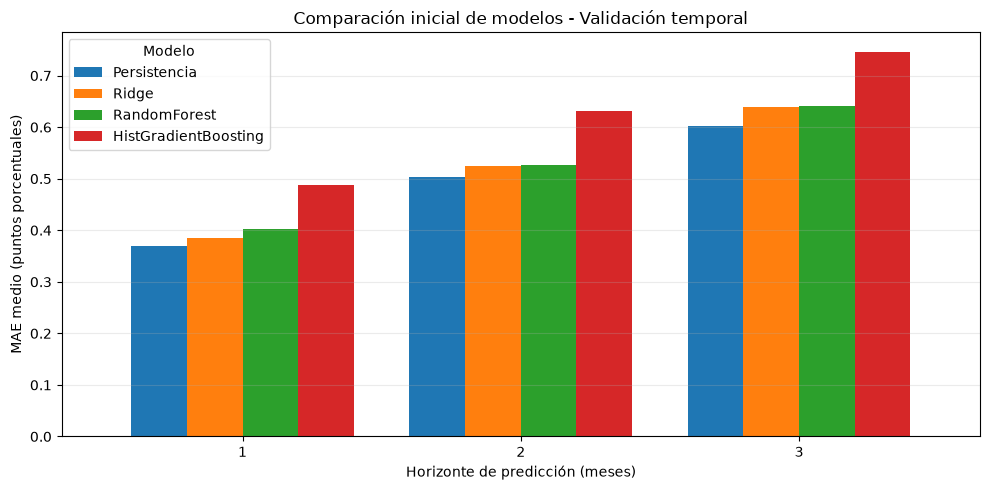

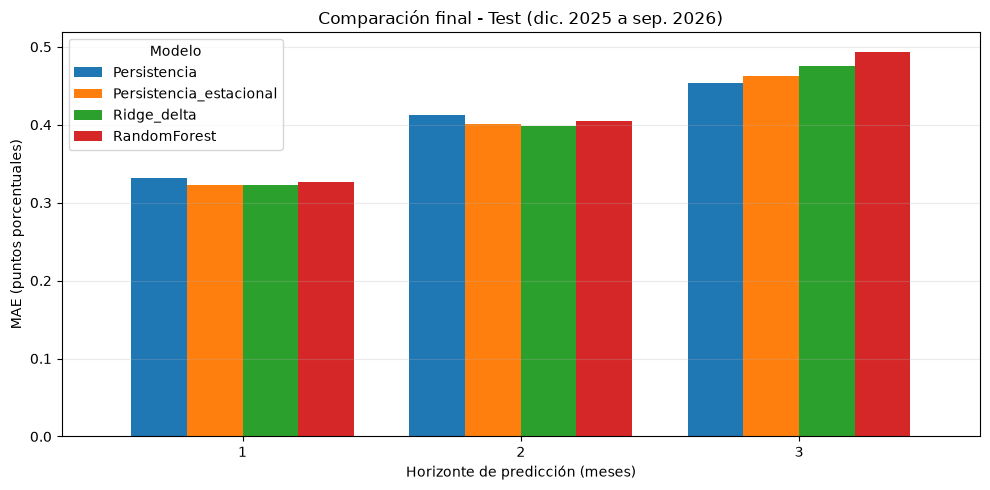

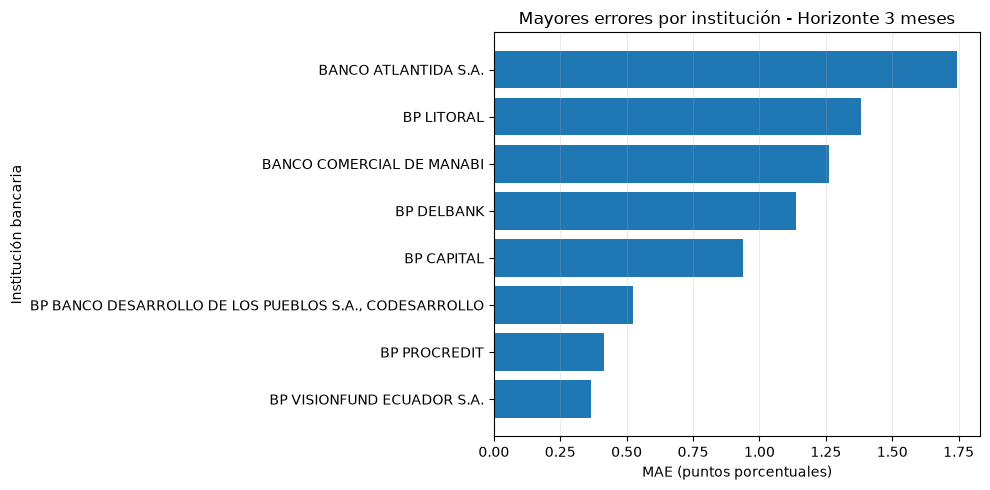


Figuras generadas en:
/home/gustavo-paredes/Documents/Developer/Yachay/morosidad-bancos-ecuador/reports/figures


In [10]:
import matplotlib.pyplot as plt

# ==========================================
# DIRECTORIO DE FIGURAS
# ==========================================

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================
# FIGURA 1: VALIDACIÓN CRUZADA INICIAL
# ==========================================

orden_modelos = [
    "Persistencia",
    "Ridge",
    "RandomForest",
    "HistGradientBoosting"
]

tabla_cv = resumen_cv.pivot(
    index="horizonte",
    columns="modelo",
    values="mae_medio"
)[orden_modelos]

ax = tabla_cv.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
    width=0.8
)

ax.set_title(
    "Comparación inicial de modelos - Validación temporal"
)
ax.set_xlabel("Horizonte de predicción (meses)")
ax.set_ylabel("MAE medio (puntos porcentuales)")
ax.legend(title="Modelo")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "01_mae_validacion_inicial.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ==========================================
# FIGURA 2: TEST EN PERÍODO COMÚN
# ==========================================

orden_final = [
    "Persistencia",
    "Persistencia_estacional",
    "Ridge_delta",
    "RandomForest"
]

tabla_test = resumen_comun.pivot(
    index="horizonte",
    columns="modelo",
    values="mae_pp"
)[orden_final]

ax = tabla_test.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
    width=0.8
)

ax.set_title(
    "Comparación final - Test (dic. 2025 a sep. 2026)"
)
ax.set_xlabel("Horizonte de predicción (meses)")
ax.set_ylabel("MAE (puntos porcentuales)")
ax.legend(title="Modelo")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "02_mae_test_periodo_comun.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ==========================================
# FIGURA 3: ERRORES POR INSTITUCIÓN
# ==========================================

top_bancos = (
    errores_banco.loc[
        errores_banco["horizonte"] == 3
    ]
    .nlargest(8, "mae_pp")
    .sort_values("mae_pp")
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    top_bancos["banco"],
    top_bancos["mae_pp"]
)

ax.set_title(
    "Mayores errores por institución - Horizonte 3 meses"
)
ax.set_xlabel("MAE (puntos porcentuales)")
ax.set_ylabel("Institución bancaria")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "03_errores_bancos_h3.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


print("\nFiguras generadas en:")
print(FIGURES_DIR)